# Is My Function Resolved?

Every computation on a grid raises the same question: are there enough grid points? The usual answer is to
repeat the computation on a finer grid and to compare. On spectral grids there is a cheaper one. A function on a
Chebyshev or periodic axis is a sum of basis functions,

$$
f(x) = \sum_{k} a_k\, T_k(x) \qquad \text{or} \qquad f(x) = \sum_k c_k\, e^{i k x},
$$

and the coefficients show directly how well the grid represents it. For a smooth function they decay
rapidly. If the last ones are negligible, the function is resolved. If they are not, the grid is too coarse,
and their decay tells how many points are missing.

In this notebook we

1. compute spectral coefficients and see how smooth and non-smooth functions differ,
2. let *numgrids* judge the resolution, in one and in two dimensions,
3. choose the number of grid points from the estimate and check the error,
4. look at aliasing in a nonlinear product and remove it with the 2/3 rule.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import iv

from numgrids import *

## Coefficients

`grid.coefficients(f)` returns the expansion coefficients of a meshed function, `grid.from_coefficients(c)`
transforms back. On a Chebyshev axis these are the coefficients $a_k$ of the Chebyshev polynomials $T_k$. For
$e^x$ on $[-1, 1]$ they are known in closed form, $a_k = 2 I_k(1)$ with the modified Bessel functions $I_k$
(and $a_0 = I_0(1)$):

In [2]:
grid = Grid(x=chebyshev(16, -1, 1))
x = grid.coords

a = grid.coefficients(np.exp(x))
exact = 2 * iv(np.arange(16), 1.0)
exact[0] /= 2

print(" k   coefficient          exact")
for k in range(0, 13, 3):
    print(f"{k:2d}   {a[k]:.12e}   {exact[k]:.12e}")

print("\nround trip error:", np.abs(grid.from_coefficients(a) - np.exp(x)).max())

 k   coefficient          exact
 0   1.266065877752e+00   1.266065877752e+00
 3   4.433684984866e-02   4.433684984866e-02
 6   4.497732295436e-05   4.497732295430e-05
 9   1.103677174187e-08   1.103677172552e-08
12   1.039120641385e-12   1.039152230679e-12

round trip error: 8.881784197001252e-16


The coefficients fall by twelve orders of magnitude within twelve modes. A polynomial of degree 14 or so
represents $e^x$ on this interval to machine precision; further grid points are wasted on it.

## Smooth or Not? The Decay of the Spectrum

How fast the coefficients decay depends on the smoothness of the function:

* For an **analytic** function they decay *geometrically*, $|a_k| \sim e^{-ck}$. The rate $c$ is set by the
  distance of the nearest singularity in the complex plane. The Runge function $1/(1 + 25x^2)$ has poles at
  $x = \pm i/5$, quite close to the interval.
* For an **entire** function (no singularities at all), like a Gaussian, the decay is even faster.
* For a function with a **kink** they decay only *algebraically*, $|a_k| \sim k^{-p}$: with $p = 2$ for
  $|x|$, whose first derivative jumps, and $p = 4$ for $|x|^3$, whose third derivative jumps.

Geometric decay is a straight line in a semi-logarithmic plot, algebraic decay is a straight line in a
doubly logarithmic plot. We compute the coefficients on a grid with 1024 points and show the lowest ones. All
four functions are even, so only the even coefficients are shown (the odd ones vanish).

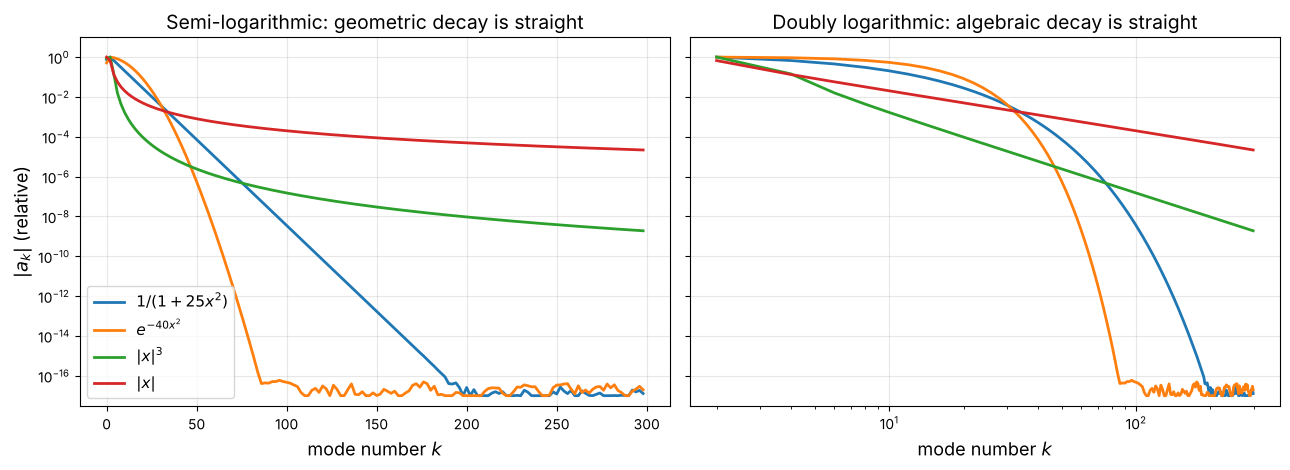

In [3]:
functions = {
    r"$1/(1+25x^2)$": lambda x: 1 / (1 + 25 * x**2),
    r"$e^{-40x^2}$": lambda x: np.exp(-40 * x**2),
    r"$|x|^3$": lambda x: np.abs(x)**3,
    r"$|x|$": lambda x: np.abs(x),
}

grid = Grid(x=chebyshev(1024, -1, 1))
x = grid.coords
k = np.arange(0, 300, 2)                           # the lowest 150 even modes

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for label, func in functions.items():
    a = np.abs(grid.coefficients(func(x)))[k]
    a = np.maximum(a / a.max(), 1e-17)             # round-off level
    ax1.semilogy(k, a, linewidth=2, label=label)
    ax2.loglog(k[1:], a[1:], linewidth=2, label=label)

ax1.set_ylim(3e-18, 10)
ax1.set_xlabel("mode number $k$", fontsize=13)
ax1.set_ylabel("$|a_k|$ (relative)", fontsize=13)
ax1.set_title("Semi-logarithmic: geometric decay is straight", fontsize=14)
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
ax2.set_xlabel("mode number $k$", fontsize=13)
ax2.set_title("Doubly logarithmic: algebraic decay is straight", fontsize=14)
ax2.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

The two smooth functions reach the round-off level of $10^{-16}$ and stay there; the two functions with a
kink never get close to it.

`grid.resolution`, which we meet in the next section, also fits the decay of the spectrum: `rate` is the
constant $c$ of a geometric decay, `order` the exponent $p$ of an algebraic one, and `decay` says which of the
two laws describes the spectrum. The rate of the Runge function must be
$c = \ln\frac{1 + \sqrt{26}}{5} \approx 0.199$, the orders of the kinks 4 and 2:

In [4]:
print("function        decay        rate c    order p")
for label, func in functions.items():
    axis = grid.resolution(func(x))["x"]
    number = f"{axis.rate:8.3f}        -" if axis.decay == "geometric" else f"       -   {axis.order:6.2f}"
    print(f"{label.strip('$'):14s}  {axis.decay:10s} {number}")

function        decay        rate c    order p
1/(1+25x^2)     geometric     0.199        -
e^{-40x^2}      geometric     0.488        -
|x|^3           algebraic         -     4.03
|x|             algebraic         -     2.19


The order of $|x|$ is only roughly right, because the highest coefficients on a grid are distorted by aliasing
(more on that below). But the verdict is clear, and the report draws the practical conclusion:

In [5]:
print(grid.resolution(np.abs(x)))

Resolution at tol=1e-08: NOT resolved
  axis x: NOT resolved, tail at 2e-05; about 1e+07 points needed (algebraic decay of order 2.2: the function is not smooth)


## The Resolution Check

`grid.resolution(f)` looks at the spectrum along each axis and answers two questions: is the function
resolved, and how many points does it need? The function counts as resolved if its highest modes (a tenth
of all modes) add up to less than a tolerance, by default $10^{-8}$ of the largest coefficient.

We try the Runge function on too few, on enough and on far too many points:

In [6]:
runge = lambda x: 1 / (1 + 25 * x**2)

results = {}
for n in (40, 120, 400):
    grid = Grid(x=chebyshev(n, -1, 1))
    results[n] = grid.resolution(runge(grid.coords))
    print(results[n])

Resolution at tol=1e-08: NOT resolved
  axis x: NOT resolved, tail at 1e-03; about 107 points needed
Resolution at tol=1e-08: resolved
  axis x: resolved, 113 of 120 points needed
Resolution at tol=1e-08: resolved
  axis x: resolved, 113 of 400 points needed


The three grids agree: the function needs about 110 points. On 120 and on 400 points this number is read off
the spectrum: the series can be chopped where the remaining coefficients add up to less than the tolerance.
On 40 points the function is not resolved, and the number is an extrapolation of the decay seen so far.

`result.plot()` shows what the check sees. The dots are the coefficients, the dashed line is the tolerance:

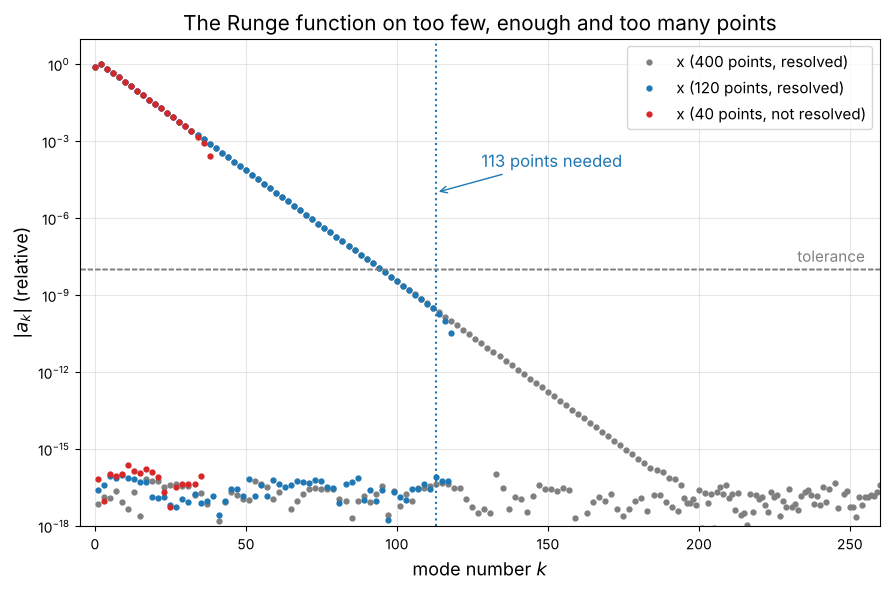

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
for n, color in zip((400, 120, 40), ("C7", "C0", "C3")):
    results[n].plot(ax=ax, color=color, markersize=7)

needed = results[400]["x"].needed
ax.axvline(needed, color="C0", linestyle=":", linewidth=1.5)
ax.annotate(f"{needed} points needed", xy=(needed, 1e-5), xytext=(needed + 15, 1e-4), fontsize=12,
            arrowprops=dict(arrowstyle="->", color="C0"), color="C0")
ax.text(255, 2e-8, "tolerance", ha="right", fontsize=11, color="gray")
ax.set_ylim(1e-18, 10)
ax.set_xlim(-5, 260)
ax.set_xlabel("mode number $k$", fontsize=13)
ax.set_ylabel("$|a_k|$ (relative)", fontsize=13)
ax.set_title("The Runge function on too few, enough and too many points", fontsize=15)
ax.legend(fontsize=11, loc="upper right")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

On 40 points (red) the spectrum ends at $10^{-3}$, far above the tolerance. On 120 points (blue) it crosses
the tolerance with a few modes to spare. On 400 points (gray) most of the modes sit on the round-off plateau
and carry no information. The lower band of dots are the odd coefficients, which vanish for an even function.

## How Many Points? Checking the Estimate

Is the estimate right? We interpolate the function from $n$ Chebyshev points to a fine set of test points and
measure the error for a range of $n$ with `convergence_study`:

In [8]:
tol = 1e-8
from_coarse = results[40]["x"].needed        # extrapolated from 40 points
from_fine = results[400]["x"].needed         # read off the spectrum on 400 points

x_test = np.linspace(-1, 1, 2001)
ns = np.arange(20, 201, 6)
study = convergence_study(
    lambda n: Grid(x=chebyshev(n, -1, 1)),
    lambda grid: grid.interpolate(runge(grid.coords), x_test, method="spectral"),
    ns=ns,
    exact=lambda grid: runge(x_test),
)

print(f"estimate from  40 points: {from_coarse}")
print(f"estimate from 400 points: {from_fine}")
print(f"smallest n with an error below {tol:g}: {ns[study.errors < tol][0]}")

estimate from  40 points: 107
estimate from 400 points: 113
smallest n with an error below 1e-08: 98


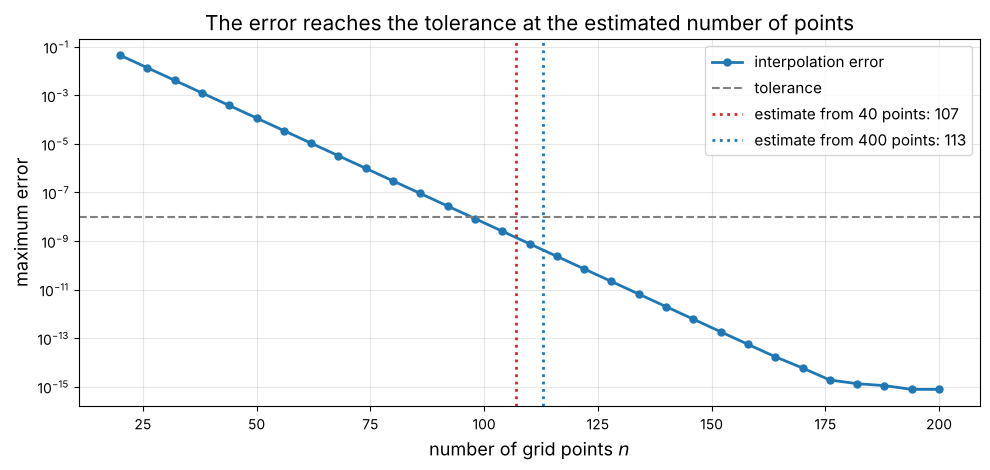

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.semilogy(study.ns, study.errors, "o-", linewidth=2, markersize=5, label="interpolation error")
ax.axhline(tol, color="gray", linestyle="--", label="tolerance")
ax.axvline(from_coarse, color="C3", linestyle=":", linewidth=2, label=f"estimate from 40 points: {from_coarse}")
ax.axvline(from_fine, color="C0", linestyle=":", linewidth=2, label=f"estimate from 400 points: {from_fine}")
ax.set_xlabel("number of grid points $n$", fontsize=13)
ax.set_ylabel("maximum error", fontsize=13)
ax.set_title("The error reaches the tolerance at the estimated number of points", fontsize=15)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

Both estimates are on the safe side by a few points: the check asks for a tenth of the modes to be negligible,
so that the next check on the new grid can confirm the result.

An over-resolved function can be transferred to the smaller grid without evaluating it again.
`grid.resample` truncates the series:

In [10]:
fine = Grid(x=chebyshev(400, -1, 1))
small = Grid(x=chebyshev(from_fine, -1, 1))

f_small = fine.resample(runge(fine.coords), small)
print(f"{fine.size} -> {small.size} points, difference to the function itself: "
      f"{np.abs(f_small - runge(small.coords)).max():.1e}")
print("still resolved:", small.is_resolved(f_small))

400 -> 113 points, difference to the function itself: 1.7e-10
still resolved: True


## Two Dimensions: Each Axis on Its Own

On a tensor-product grid each axis has its own resolution. The function

$$
f(x, y) = \tanh(10x)\, e^{\sin y}
$$

has a steep front in $x$ and is very smooth in the periodic direction $y$. A grid with 40 × 64 points is too
coarse in $x$ and wastes points in $y$:

In [11]:
func = lambda x, y: np.tanh(10 * x) * np.exp(np.sin(y))

grid = Grid(x=chebyshev(40, -1, 1), y=periodic(64))
result = grid.resolution(grid.evaluate(func))
print(result)

Resolution at tol=1e-08: NOT resolved
  axis x: NOT resolved, tail at 2e-03; about 159 points needed
  axis y: resolved, 20 of 64 points needed


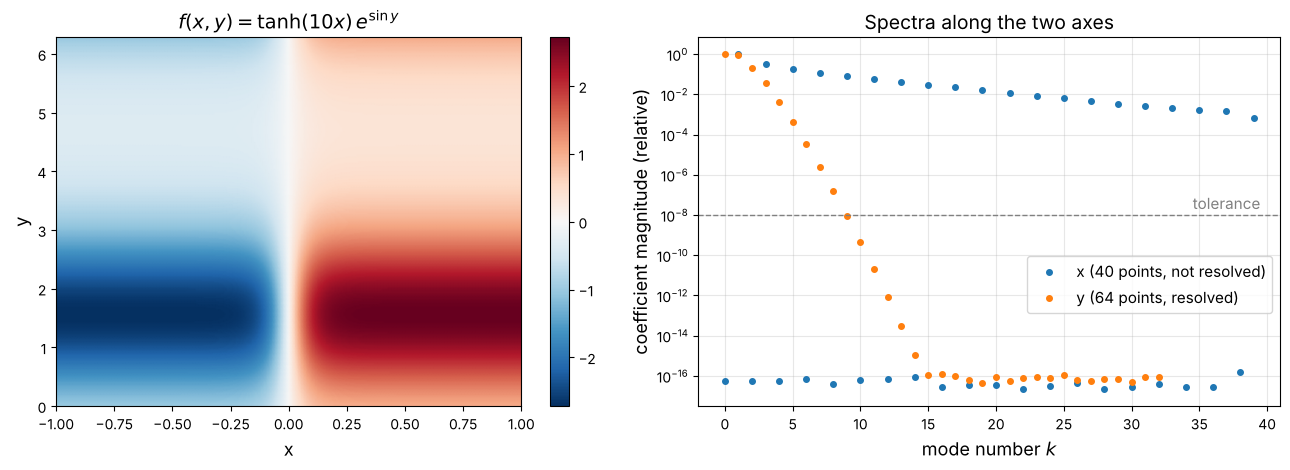

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

xs, ys = np.linspace(-1, 1, 300), np.linspace(0, 2 * np.pi, 300)
im = ax1.pcolormesh(xs, ys, func(*np.meshgrid(xs, ys)), cmap="RdBu_r", shading="gouraud", rasterized=True)
fig.colorbar(im, ax=ax1)
ax1.set_xlabel("x", fontsize=13)
ax1.set_ylabel("y", fontsize=13)
ax1.set_title(r"$f(x, y) = \tanh(10x)\, e^{\sin y}$", fontsize=14)

result.plot(ax=ax2, markersize=8)
ax2.text(39.5, 2e-8, "tolerance", ha="right", fontsize=11, color="gray")
ax2.set_xlabel("mode number $k$", fontsize=13)
ax2.set_ylabel("coefficient magnitude (relative)", fontsize=13)
ax2.set_title("Spectra along the two axes", fontsize=14)
ax2.legend(fontsize=11, loc="center right", bbox_to_anchor=(1.0, 0.33))
ax2.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

The spectrum along $y$ (a Fourier series, mode $k$ is the amplitude of the wavenumber $k$) is at round-off
level after ten modes. The spectrum along $x$ has only fallen to $10^{-3}$.

`result.suggested_grid` is a grid of the same type with the suggested numbers of points. We check the
resolution on it, and the actual error at random points:

In [13]:
better = result.suggested_grid
print("suggested shape:", better.shape)
print(better.resolution(better.evaluate(func)))

rng = np.random.default_rng(0)
points = np.column_stack([rng.uniform(-1, 1, 1000), rng.uniform(0, 2 * np.pi, 1000)])
print()
for g in (grid, better):
    values = g.interpolate(g.evaluate(func), points, method="spectral")
    error = np.abs(values - func(points[:, 0], points[:, 1])).max()
    print(f"shape {str(g.shape):10s} {g.size:5d} points   maximum error {error:.1e}")

suggested shape: (159, 20)
Resolution at tol=1e-08: resolved
  axis x: resolved, 132 of 159 points needed
  axis y: resolved, 20 of 20 points needed

shape (40, 64)    2560 points   maximum error 7.4e-03
shape (159, 20)   3180 points   maximum error 1.2e-10


With about the same total number of points, the error drops from $10^{-2}$ to $10^{-10}$: the points are
now where the function needs them. Following the suggestion once more would trim the $x$ axis to the 132
points that it really needs.

## Aliasing and the 2/3 Rule

A grid with $n$ periodic points represents the wavenumbers up to $n/2$. A product of two functions contains
wavenumbers up to the *sum* of their highest ones, and what does not fit does not disappear. On 32 points
the wavenumber 20 looks exactly like the wavenumber $32 - 20 = 12$:

$$
\cos^2(10x) = \tfrac12 + \tfrac12 \cos(20x) .
$$

In [14]:
grid = Grid(x=periodic(32))
x = grid.coords
u = np.cos(10 * x)

def waves(f):
    c = grid.coefficients(f)             # c_k for k = 0, 1, ..., 16 come first
    present = np.flatnonzero(np.abs(c[1:17]) > 1e-12) + 1
    return f"mean value {c[0].real:.3f}, wavenumbers {present}, amplitudes {2 * np.abs(c[present])}"

print("u*u on the grid:      ", waves(u * u))
print("filtered:             ", waves(grid.filter(u * u)))

u*u on the grid:       mean value 0.500, wavenumbers [12], amplitudes [0.5]
filtered:              mean value 0.500, wavenumbers [], amplitudes []


The product computed on the grid contains a wave with $k = 12$ that the true product does not have. This is
*aliasing*. In a time stepping scheme for a nonlinear equation such errors feed back into the solution in
every step and can make the computation unstable.

`grid.filter` removes it. By default it is a low-pass filter that keeps the lowest two thirds of the modes
(here $k \le 10$). The reason for *two thirds*: if both factors only contain modes up to $n/3$, their product
reaches $2n/3$, and the aliased part lands between $n/3$ and $n/2$, in the third that the filter removes.
The modes that are kept stay exact.

Let us see this for a function with a broad spectrum. We compare the square computed on a grid with 48
points with the true square, computed on a much finer grid:

In [15]:
profile = lambda x: 0.005 / (1.005 - np.cos(x))

grid = Grid(x=periodic(48))
fine = Grid(x=periodic(384))
x = grid.coords
amplitudes = lambda g, f: g.resolution(f)["x"].spectrum      # amplitude of each wavenumber

u = grid.filter(profile(x))                                  # contains the wavenumbers k <= 15
true_square = amplitudes(fine, grid.resample(u, fine)**2)[:25]
on_grid = amplitudes(grid, u * u)
dealiased = amplitudes(grid, grid.filter(u * u))

kept = np.arange(16)
print(f"error of the modes k <= 15:  {np.abs(on_grid - true_square)[kept].max():.1e}")
print(f"error of the modes k > 15:   {np.abs(on_grid - true_square)[16:].max():.1e}   (aliasing)")

raw = profile(x)                                             # without the filter: k <= 24
raw_true = amplitudes(fine, grid.resample(raw, fine)**2)[:25]
print(f"\nwithout filtering the factor first, the modes k <= 15 are wrong by "
      f"{np.abs(amplitudes(grid, raw * raw) - raw_true)[kept].max():.1e}")

error of the modes k <= 15:  2.1e-17
error of the modes k > 15:   3.1e-03   (aliasing)

without filtering the factor first, the modes k <= 15 are wrong by 4.7e-03


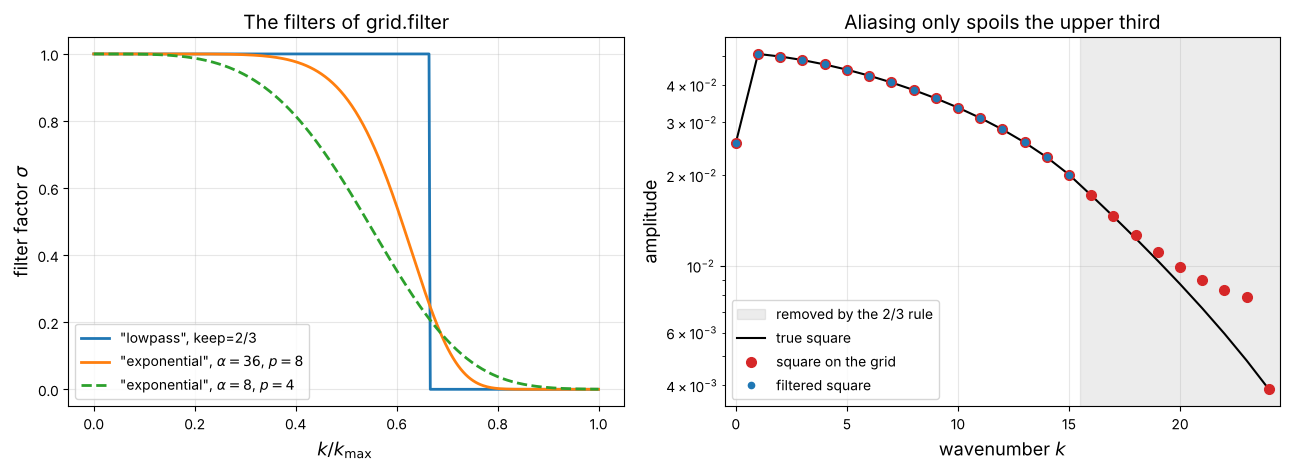

In [16]:
eta = np.linspace(0, 1, 400)
k = np.arange(25)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

ax1.plot(eta, eta < 2 / 3, linewidth=2, label='"lowpass", keep=2/3')
ax1.plot(eta, np.exp(-36 * eta**8), linewidth=2, label=r'"exponential", $\alpha = 36$, $p = 8$')
ax1.plot(eta, np.exp(-8 * eta**4), linewidth=2, linestyle="--", label=r'"exponential", $\alpha = 8$, $p = 4$')
ax1.set_xlabel(r"$k / k_{\max}$", fontsize=13)
ax1.set_ylabel(r"filter factor $\sigma$", fontsize=13)
ax1.set_title("The filters of grid.filter", fontsize=14)
ax1.legend(fontsize=10, loc="lower left")
ax1.grid(True, alpha=0.3)

ax2.axvspan(15.5, 24.5, color="gray", alpha=0.15, label="removed by the 2/3 rule")
ax2.semilogy(k, true_square, "-", color="k", linewidth=1.5, label="true square")
ax2.semilogy(k, on_grid, "o", color="C3", markersize=7, label="square on the grid")
ax2.semilogy(k[:16], dealiased[:16], ".", color="C0", markersize=9, label="filtered square")
ax2.set_xlim(-0.5, 24.5)
ax2.set_xlabel("wavenumber $k$", fontsize=13)
ax2.set_ylabel("amplitude", fontsize=13)
ax2.set_title("Aliasing only spoils the upper third", fontsize=14)
ax2.legend(fontsize=10, loc="lower left")
ax2.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

The square on the grid (red) agrees with the true one up to $k = 15$ and is wrong above; the filter cuts
exactly there.

The left panel shows the filter factors. Besides the sharp truncation there is a smooth exponential filter,
`grid.filter(f, "exponential")`. It damps the highest modes to round-off level and leaves the lower ones almost
untouched, which is often enough to keep a nonlinear time stepping scheme stable. Both filters work on all
spectral axes, also on Chebyshev axes; there they change the boundary values, so boundary conditions have to be
imposed after filtering.

## What the Check Cannot See

The check only knows the values on the grid. Two things can mislead it.

**Aliasing.** A function that oscillates too fast for the grid looks like a slow one. On 16 points, $\sin(20x)$
has the same values as $\sin(4x)$, and passes:

In [17]:
grid = Grid(x=periodic(16))
print(grid.resolution(np.sin(20 * grid.coords)))

Resolution at tol=1e-08: resolved
  axis x: resolved, 12 of 16 points needed


**Noise and jumps.** Their spectra do not decay. The check then reports that the function is not resolved
and that more points will not help. This is a useful warning in itself: for data with noise of size
$10^{-5}$ there is no point in asking for eight digits.

In [18]:
grid = Grid(x=chebyshev(100, -1, 1))
x = grid.coords
rng = np.random.default_rng(1)

print(grid.resolution(np.exp(x) + 1e-5 * rng.standard_normal(100)))
print(grid.resolution(np.exp(x) + 1e-5 * rng.standard_normal(100), tol=1e-3))
print(grid.resolution(np.sign(x - 0.1)))

Resolution at tol=1e-08: NOT resolved
  axis x: NOT resolved, tail at 6e-06 and not decaying (100 points: too few, or the data is noisy or not smooth)
Resolution at tol=0.001: resolved
  axis x: resolved, 7 of 100 points needed
Resolution at tol=1e-08: NOT resolved
  axis x: NOT resolved, tail at 1e-01 and not decaying (100 points: too few, or the data is noisy or not smooth)


## Summary

* `grid.coefficients(f)` and `grid.from_coefficients(c)` transform between values and spectral coefficients:
  Chebyshev coefficients on Chebyshev axes, Fourier coefficients on periodic axes.
* The decay of the coefficients shows the smoothness of a function: geometric for analytic functions, algebraic
  for functions with kinks.
* `grid.resolution(f)` reports for each axis whether the function is resolved and how many points it needs;
  `result.suggested_grid` is the grid to try next, `result.plot()` shows the spectra.
* `grid.resample(f, shape)` changes the number of points in coefficient space.
* `grid.filter(f)` truncates the spectrum (2/3 rule against aliasing) or damps it smoothly.

The check costs a few fast transforms and needs no second grid. For quantities that are not functions on a
spectral grid (an integral, an eigenvalue, a finite-difference solution), use `convergence_study` or `adapt`.